# Imports and Configs

In [20]:
import os, datetime, warnings
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import numpy as np


warnings.filterwarnings("ignore")

# ── Config ────────────────────────────────────────────────────────────────
DATA_DIR       = "data"
TARGET_SEASON  = 2026
WINDOW_N       = 3              # use last N seasons before TARGET_SEASON in train
SPLIT_DATE     = datetime.date(2026, 4, 12)   # train < SPLIT_DATE, test >= SPLIT_DATE
N_OVERS_OBS    = 3
N_OVERS_TARGET = 6


# Download and Extract IPL Dataset



This cell downloads the IPL ball-by-ball dataset from the official
[Cricsheet](https://cricsheet.org/?utm_source=chatgpt.com) repository, extracts the CSV files into a local `data/` directory, and removes the downloaded `.zip` archive afterward to save space.

What this code does
1. Creates a `data/` folder if it does not already exist.
2. Downloads the compressed IPL dataset.
3. Extracts all files from the ZIP archive.
4. Deletes the ZIP file after extraction.
5. Stores the final dataset inside `data/`.

> After running this cell, all match CSV files will be available in:
>
> ```python
> data/
> ```

In [21]:
import urllib.request
import zipfile

# Paths
DATA_DIR = "data/"
ZIP_URL = "https://cricsheet.org/downloads/ipl_male_csv2.zip"
ZIP_PATH = os.path.join(DATA_DIR, "ipl_male_csv2.zip")

os.makedirs(DATA_DIR, exist_ok=True)

# Download
urllib.request.urlretrieve(ZIP_URL, ZIP_PATH)

# Extract
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(DATA_DIR)

os.remove(ZIP_PATH)

print("Done. Files are in:", DATA_DIR)

Done. Files are in: data/


# Preprocessing IPL Match Data and Feature Engineering



The below cell defines helper functions for working with the IPL dataset downloaded from
[Cricsheet](https://cricsheet.org/?utm_source=chatgpt.com).

Each match contains:
- `MATCH_ID.csv` → ball-by-ball data
- `MATCH_ID_info.csv` → metadata about the match

These helper functions are used for loading, cleaning, and processing the data.

---

Function Summaries

| Function | Purpose |
|---|---|
| `load_match_ids()` | Returns all valid match IDs that have both metadata and ball-by-ball files. |
| `parse_info()` | Given the string object output of read_info(), it converts it into a usable python dictionary |
| `read_info()` | Takes the {match_id}_info.csv as input and returns its contents as a python string object |
| `read_bbb()` | Loads the ball-by-ball CSV into a cleaned Pandas DataFrame, also creates a new column "Total_runs" |
| `match_date()` | Extracts the date of the match as a `datetime.date` object. |
| `match_year()` | Extracts only the year from the match date. |


In [22]:
def load_match_ids(d=DATA_DIR):
    files = os.listdir(d)
    info = {f[:-9] for f in files if f.endswith("_info.csv")}
    ball = {f[:-4] for f in files if f.endswith(".csv") and "_info" not in f}
    return sorted(info & ball)

def parse_info(text):
    info = {}
    for line in text.strip().split("\n"):
        p = line.strip().split(",")
        if len(p) < 3 or p[0] != "info":
            continue
        k, v = p[1].strip(), ",".join(p[2:]).strip()
        if k in ("winner","winner_runs","winner_wickets","outcome","result"):
            continue
        if k in info:
            info[k] = info[k] + [v] if isinstance(info[k], list) else [info[k], v]
        else:
            info[k] = v
    return info

def read_info(mid, d=DATA_DIR):
    with open(os.path.join(d, f"{mid}_info.csv")) as f:
        return parse_info(f.read())

def read_bbb(mid, d=DATA_DIR):
    df = pd.read_csv(os.path.join(d, f"{mid}.csv"))
    df["runs_off_bat"] = pd.to_numeric(df.get("runs_off_bat", 0), errors="coerce").fillna(0)
    df["extras"]       = pd.to_numeric(df.get("extras", 0),       errors="coerce").fillna(0)
    df["total_runs"]   = df["runs_off_bat"] + df["extras"]
    return df

def match_date(info):
    """Return earliest match date as datetime.date, or None."""
    d = info.get("date")
    if isinstance(d, list): d = d[0]
    if d:
        try:
            return datetime.datetime.strptime(d, "%Y/%m/%d").date()
        except Exception:
            pass
    s = info.get("season", "")
    if isinstance(s, list): s = s[0]
    try:
        return datetime.date(int(str(s)[:4]), 1, 1)
    except Exception:
        return None

def match_year(info):
    d = match_date(info)
    return d.year if d else None

all_ids = load_match_ids()
print(f"Total matches on disk: {len(all_ids)}")




Total matches on disk: 1226


(Extract Match Dates and Count Matches by Season
) The below cell does the following
- map each match ID to its match date
- extract the corresponding season/year
- count how many matches exist per year
- verify that the target season exists in the dataset

In [23]:
id_to_date = {}
for mid in all_ids:
    try:
        d = match_date(read_info(mid))
        if d is not None:
            id_to_date[mid] = d
    except Exception:
        pass

id_to_year = {m: d.year for m, d in id_to_date.items()}
season_counts = pd.Series(list(id_to_year.values())).value_counts().sort_index()
print(season_counts.to_string())
assert TARGET_SEASON in season_counts.index, f"No {TARGET_SEASON} matches found in {DATA_DIR}"
print(f"\n✅ {TARGET_SEASON} matches: {int(season_counts[TARGET_SEASON])}")

2008    58
2009    57
2010    60
2011    73
2012    74
2013    76
2014    60
2015    59
2016    60
2017    59
2018    60
2019    60
2020    60
2021    60
2022    74
2023    74
2024    71
2025    74
2026    57

✅ 2026 matches: 57


Function Summaries for the below cell

| Function | Purpose |
|---|---|
| `first_innings()` | Extracts only the first-innings deliveries from the ball-by-ball DataFrame. |
| `score_at()` | Computes the batting score before a specified over. |
| `count_wkts()` | Counts the number of wickets lost in a DataFrame. |
| `batting_team()` | Determines which team batted first using toss information or fallback logic. |
| `bowling_team()` | Determines which team bowled first using the batting team information. |


In [24]:
def first_innings(bbb):
    df = bbb[bbb["innings"] == 1].copy() if "innings" in bbb.columns else bbb.copy()
    df["over_num"] = df["ball"].apply(lambda b: int(float(str(b).split(".")[0])))
    return df

def score_at(df1, end_over):
    return float(df1[df1["over_num"] < end_over]["total_runs"].sum())

def count_wkts(df):
    if "wickets" in df.columns:
        return int(pd.to_numeric(df["wickets"], errors="coerce").fillna(0).sum())
    if "player_dismissed" in df.columns:
        return int(df["player_dismissed"].notna().sum())
    return 0

def batting_team(info, df1):
    teams = info.get("team", [])
    if isinstance(teams, str): teams = [teams]
    tw, td = info.get("toss_winner",""), info.get("toss_decision","").lower()
    if td in ("bat","batting"): return tw
    if td in ("field","fielding") and len(teams)==2:
        return [t for t in teams if t!=tw][0] if tw in teams else teams[0]
    if "batting_team" in df1.columns:
        v = df1["batting_team"].dropna().unique()
        if len(v): return v[0]
    return teams[0] if teams else "unknown"

def bowling_team(info, df1):
    teams = info.get("team", [])
    if isinstance(teams, str): teams = [teams]
    bt = batting_team(info, df1)
    other = [t for t in teams if t != bt]
    return other[0] if other else "unknown"

The below cell contains two functions, build_player_maps and compute_hist_stats which return the following:

1) build_player_maps: Builds historical player-level and batter-vs-bowler statistics from the training matches. Returns the following engineered features

| Variable | Meaning |
|---|---|
| `striker_avg` | Average powerplay runs scored by each striker |
| `non_striker_avg` | Average runs while appearing as non-striker |
| `bowler_avg` | Bowler economy rate (runs conceded per ball) |
| `striker_sr` | Batter strike rate |
| `non_striker_sr` | Non-striker strike rate |
| `striker_bdry` | Batter boundary frequency |
| `bowler_wrate` | Bowler wicket-taking rate |
| `star_strikers` | List of elite/high-performing batters |
| `h2h_runs` | Historical runs scored by batter against bowler |
| `h2h_balls` | Historical balls faced in batter-vs-bowler matchup |
| `h2h_wkts` | Historical dismissals in batter-vs-bowler matchup |
| `gs` | Global striker average |
| `gns` | Global non-striker average |
| `gb` | Global bowler economy |
| `gsr` | Global striker strike rate |
| `gnsr` | Global non-striker strike rate |
| `gbd` | Global boundary rate |
| `gbw` | Global wicket rate |

<br>

2) compute_hist_stats: Returns engineered features that capture overall IPL-wide scoring behavior.

| Variable | Meaning |
|---|---|
| `g6` | Global average score after 6 overs |
| `g3` | Global average score after 3 overs |
| `HIGH` | Threshold defining a high-scoring powerplay |
| `g_high_freq` | Fraction of matches with 60+ PP score |
| `g_bdry` | Global powerplay boundary frequency |
| `g_w6` | Average wickets lost in first 6 overs |
| `venue_pp` | Average PP score at each venue |
| `venue_3` | Average score after 3 overs at each venue |
| `venue_high_freq` | Frequency of 60+ PP scores at each venue |
| `venue_bdry` | Boundary frequency at each venue |
| `team_pp` | Average PP score by batting team |
| `team_w` | Average wickets lost by batting team in first 3 overs |
| `team_high_freq` | Frequency of explosive PPs by batting team |
| `team_bdry` | Boundary frequency of batting team |
| `bowl_pp` | Average PP score conceded by bowling team |
| `bowl_high_freq` | Frequency of 60+ PPs conceded by bowling team |




In [25]:
def build_player_maps(train_ids):
    """Target-encode players + build batter↔bowler H2H table (train_ids only)."""
    s_runs, s_balls, s_bdry      = {}, {}, {}
    ns_runs, ns_balls, ns_bdry   = {}, {}, {}
    b_runs, b_balls, b_wkts      = {}, {}, {}
    h2h_runs, h2h_balls, h2h_wkts = {}, {}, {}     # key = (striker, bowler)

    for mid in train_ids:
        try:
            df1 = first_innings(read_bbb(mid))
            pp  = df1[df1["over_num"] < 6]
            for s, g in pp.groupby("striker"):
                runs, balls = float(g["runs_off_bat"].sum()), len(g)
                bdry = int(((g["runs_off_bat"]==4)|(g["runs_off_bat"]==6)).sum())
                s_runs.setdefault(s, []).append(runs)
                s_balls.setdefault(s, []).append(balls)
                s_bdry.setdefault(s, []).append(bdry)
            for ns, g in pp.groupby("non_striker"):
                runs, balls = float(g["runs_off_bat"].sum()), len(g)
                ns_runs.setdefault(ns, []).append(runs)
                ns_balls.setdefault(ns, []).append(balls)
                ns_bdry.setdefault(ns, []).append(0)
            for b, g in pp.groupby("bowler"):
                if len(g) >= 3:
                    b_runs.setdefault(b, []).append(float(g["total_runs"].sum()))
                    b_balls.setdefault(b, []).append(len(g))
                    if "player_dismissed" in g.columns:
                        b_wkts.setdefault(b, []).append(int(g["player_dismissed"].notna().sum()))

            # H2H: any innings (not just PP) — broader sample → more matchups
            full = df1[["striker","bowler","runs_off_bat","total_runs","player_dismissed"]].copy() \
                   if "player_dismissed" in df1.columns else df1[["striker","bowler","runs_off_bat","total_runs"]].assign(player_dismissed=np.nan)
            for (s, b), g in full.groupby(["striker","bowler"]):
                key = f"{s}@{b}"
                h2h_runs[key]  = h2h_runs.get(key, 0.0) + float(g["runs_off_bat"].sum())
                h2h_balls[key] = h2h_balls.get(key, 0)  + len(g)
                h2h_wkts[key]  = h2h_wkts.get(key, 0)   + int(g["player_dismissed"].notna().sum())
        except Exception:
            continue

    def _avg(d):
        return {k: float(np.mean(v)) for k, v in d.items()} if d else {}

    def _sr(runs_d, balls_d):
        out = {}
        for k in runs_d:
            tb = float(np.sum(balls_d.get(k, [0])))
            tr = float(np.sum(runs_d[k]))
            if tb >= 6:
                out[k] = 100.0 * tr / tb
        return out

    striker_sr     = _sr(s_runs,  s_balls)
    non_striker_sr = _sr(ns_runs, ns_balls)
    striker_bdry   = {k: float(np.sum(s_bdry[k]))/max(float(np.sum(s_balls[k])),1) for k in s_runs if np.sum(s_balls[k])>=6}
    bowler_econ    = {k: float(np.sum(b_runs[k]))/max(float(np.sum(b_balls[k])),1) for k in b_runs}
    bowler_wrate   = {k: float(np.sum(b_wkts.get(k,[0])))/max(float(np.sum(b_balls[k])),1) for k in b_runs}

    gs   = float(np.mean([np.mean(v) for v in s_runs.values()]))   if s_runs   else 20.0
    gns  = float(np.mean([np.mean(v) for v in ns_runs.values()]))  if ns_runs  else 15.0
    gsr  = float(np.mean(list(striker_sr.values())))     if striker_sr     else 130.0
    gnsr = float(np.mean(list(non_striker_sr.values()))) if non_striker_sr else 120.0
    gbd  = float(np.mean(list(striker_bdry.values())))   if striker_bdry   else 0.15
    gb   = float(np.mean(list(bowler_econ.values())))    if bowler_econ    else 1.2
    gbw  = float(np.mean(list(bowler_wrate.values())))   if bowler_wrate   else 0.03

    striker_avg = _avg(s_runs)
    if striker_avg:
        thr = float(np.quantile(list(striker_avg.values()), 0.85))
        star_strikers = list({k for k, v in striker_avg.items() if v >= thr})
    else:
        thr, star_strikers = 0.0, []

    return {
        "striker_avg":     striker_avg,
        "non_striker_avg": _avg(ns_runs),
        "bowler_avg":      bowler_econ,
        "striker_sr":      striker_sr,
        "non_striker_sr":  non_striker_sr,
        "striker_bdry":    striker_bdry,
        "bowler_wrate":    bowler_wrate,
        "star_strikers":   star_strikers,
        # H2H
        "h2h_runs":  h2h_runs,
        "h2h_balls": h2h_balls,
        "h2h_wkts":  h2h_wkts,
        # globals
        "gs": gs, "gns": gns, "gb": gb,
        "gsr": gsr, "gnsr": gnsr, "gbd": gbd, "gbw": gbw,
    }

def compute_hist_stats(train_ids):
    rows = []
    for mid in train_ids:
        try:
            info = read_info(mid); df1 = first_innings(read_bbb(mid))
            pp6 = df1[df1["over_num"] < 6]
            n_pp = max(len(pp6), 1)
            rows.append({
                "venue": info.get("venue","unknown"),
                "bat":   batting_team(info, df1),
                "bowl":  bowling_team(info, df1),
                "s3":    score_at(df1, 3),
                "s6":    score_at(df1, 6),
                "w3":    count_wkts(df1[df1["over_num"] < 3]),
                "w6":    count_wkts(pp6),
                "bdry6": int(((pp6["runs_off_bat"]==4)|(pp6["runs_off_bat"]==6)).sum()) / n_pp,
            })
        except Exception:
            continue
    df = pd.DataFrame(rows)
    df = df[df["s6"] > 0]
    g6, g3 = float(df["s6"].mean()), float(df["s3"].mean())
    HIGH = 60.0

    return {
        "g6": g6, "g3": g3, "HIGH": HIGH,
        "g_high_freq": float((df["s6"] >= HIGH).mean()),
        "g_bdry":      float(df["bdry6"].mean()),
        "g_w6":        float(df["w6"].mean()),
        # batting-side venue / team (slimmed: dropped low-importance "_3" / "_std")
        "venue_pp":        df.groupby("venue")["s6"].mean().to_dict(),
        "venue_3":         df.groupby("venue")["s3"].mean().to_dict(),
        "venue_high_freq": df.groupby("venue")["s6"].apply(lambda s: float((s>=HIGH).mean())).to_dict(),
        "venue_bdry":      df.groupby("venue")["bdry6"].mean().to_dict(),
        "team_pp":         df.groupby("bat")["s6"].mean().to_dict(),
        "team_w":          df.groupby("bat")["w3"].mean().to_dict(),
        "team_high_freq":  df.groupby("bat")["s6"].apply(lambda s: float((s>=HIGH).mean())).to_dict(),
        "team_bdry":       df.groupby("bat")["bdry6"].mean().to_dict(),
        # bowling team
        "bowl_pp":         df.groupby("bowl")["s6"].mean().to_dict(),
        "bowl_high_freq":  df.groupby("bowl")["s6"].apply(lambda s: float((s>=HIGH).mean())).to_dict(),
    }


The below cells constructs the required dataset that includes the engineered features

In [26]:
def extract_features(info, df3, hist, pmaps):
    f = {}
    total = float(df3["total_runs"].sum())
    # ── (1) match state ──────────────────────────────────────────────────
    f["score_3ov"]              = total

    # ── (4) batting players ──────────────────────────────────────────────
    gs, gns = pmaps["gs"], pmaps["gns"]
    gnsr= pmaps["gnsr"]
    sm, nsm = pmaps["striker_avg"], pmaps["non_striker_avg"]
    nssr = pmaps["non_striker_sr"]
    stars = pmaps["star_strikers"]

    s_last  = df3["striker"].dropna().iloc[-1]     if "striker" in df3 and len(df3) else None
    ns_last = df3["non_striker"].dropna().iloc[-1] if "non_striker" in df3 and len(df3) else None

    striker_pp_avg     = sm.get(s_last, gs)   if s_last  is not None else gs
    non_striker_pp_avg = nsm.get(ns_last, gns) if ns_last is not None else gns
    f["non_striker_sr"]     = nssr.get(ns_last, gnsr) if ns_last is not None else gnsr
    f["pair_explosive"]     = (striker_pp_avg + non_striker_pp_avg) / 2.0
    f["star_non_striker"]   = 1.0 if (ns_last in stars) else 0.0

    # ── (6) venue / team / bowling-team priors ───────────────────────────
    bt    = batting_team(info, df3)
    g6 = hist["g6"]
    venue = info.get("venue","unknown")
    f["venue_pp_avg"]      = hist["venue_pp"].get(venue, g6)
    f["venue_bdry_rate"]   = hist["venue_bdry"].get(venue, hist["g_bdry"])
    f["venue_high_freq"]   = hist["venue_high_freq"].get(venue, hist["g_high_freq"])
    f["team_bdry_rate"]    = hist["team_bdry"].get(bt, hist["g_bdry"])
    f["team_w3_avg"]       = hist["team_w"].get(bt, 1.5)
    return f

def build_dataset(ids, hist, pmaps):
    X, y = [], []
    for mid in ids:
        try:
            info = read_info(mid); df1 = first_innings(read_bbb(mid))
            df3  = df1[df1["over_num"] < N_OVERS_OBS]
            s6   = score_at(df1, N_OVERS_TARGET)
            s3   = score_at(df1, N_OVERS_OBS)
            if s6 == 0 or len(df3) == 0:
                continue
            X.append(extract_features(info, df3, hist, pmaps))
            y.append(s6 - s3)         # delta target
        except Exception as e:
            print(e)
            continue
    Xdf = pd.DataFrame(X).fillna(0)
    yarray = np.array(y)
    return Xdf, yarray


In [27]:
# ── RF feature set: classical cricket analytics, ball-by-ball derived ─────
# Goal: capture variance / higher-scoring innings → noisier signal but RF
# averages across many trees so it under-reacts vs XGBoost.

def extract_rf_features(info, df3, hist, pmaps):
    """Cricket-analyst style features: per-over breakdown, ball-by-ball
    micro-stats, partnership, bowler usage. NO H2H, NO target encoding
    quantiles — all hand-crafted from the ball stream."""
    f = {}
    n = max(len(df3), 1)
    total = float(df3["total_runs"].sum())
    runs_bat = float(df3["runs_off_bat"].sum())
    extras   = float(df3["extras"].sum())

    # ── Per-over runs (ball-by-ball) ─────────────────────────────────────
    over_runs = {ov: float(df3[df3["over_num"] == ov]["total_runs"].sum()) for ov in range(3)}
    over_wkts = {ov: count_wkts(df3[df3["over_num"] == ov]) for ov in range(3)}
    ov1, ov2, ov3 = over_runs[0], over_runs[1], over_runs[2]

    f["score_3ov"]   = total          # required for delta reconstruction
    f["runs_off_bat"] = runs_bat
    f["extras_3ov"]  = extras
    f["over1_runs"]  = ov1
    f["over2_runs"]  = ov2
    f["over3_runs"]  = ov3
    f["over1_wkts"]  = over_wkts[0]
    f["over2_wkts"]  = over_wkts[1]
    f["over3_wkts"]  = over_wkts[2]

    # ── Run-rate dynamics ────────────────────────────────────────────────
    f["run_rate_3ov"]    = total / 3.0
    f["run_rate_slope"]  = (ov3 - ov1)                 # accel last over vs first
    f["recent_over_rr"]  = ov3                          # momentum
    f["rr_volatility"]   = float(np.std([ov1, ov2, ov3]))
    f["accel_ratio"]     = (ov3 + 1.0) / (ov1 + 1.0)

    # ── Ball-by-ball texture ─────────────────────────────────────────────
    rb = df3["runs_off_bat"]
    fours  = int((rb == 4).sum())
    sixes  = int((rb == 6).sum())
    threes = int((rb == 3).sum())
    twos   = int((rb == 2).sum())
    ones   = int((rb == 1).sum())
    dots   = int((df3["total_runs"] == 0).sum())

    f["fours"]            = fours
    f["sixes"]            = sixes
    f["boundaries"]       = fours + sixes
    f["twos"]             = twos
    f["ones"]             = ones
    f["dots"]             = dots
    f["dot_pct"]          = dots / n
    f["boundary_pct"]     = (fours + sixes) / n
    f["singles_pct"]      = ones / n
    f["scoring_balls"]    = n - dots
    f["balls_per_bdry"]   = n / max(fours + sixes, 1)

    # ── Last-6-ball micro-momentum (final over of the powerplay window) ──
    last6 = df3.tail(6)
    if len(last6) > 0:
        f["last6_runs"]  = float(last6["total_runs"].sum())
        f["last6_bdry"]  = int(((last6["runs_off_bat"]==4) | (last6["runs_off_bat"]==6)).sum())
        f["last6_dots"]  = int((last6["total_runs"] == 0).sum())
    else:
        f["last6_runs"] = f["last6_bdry"] = f["last6_dots"] = 0

    # balls since last boundary / wicket (pressure proxy)
    bdry_idx = np.where(((rb.values == 4) | (rb.values == 6)))[0]
    f["balls_since_bdry"] = float(n - 1 - bdry_idx[-1]) if len(bdry_idx) else float(n)

    if "player_dismissed" in df3.columns:
        wk_idx = np.where(df3["player_dismissed"].notna().values)[0]
        f["balls_since_wkt"] = float(n - 1 - wk_idx[-1]) if len(wk_idx) else float(n)
    else:
        f["balls_since_wkt"] = float(n)

    # ── Wicket pressure ──────────────────────────────────────────────────
    wkts = count_wkts(df3)
    f["wickets_3ov"]            = wkts
    f["wickets_remaining"]      = 10 - wkts
    f["wicket_pressure_index"]  = wkts * max(30 - total, 0)
    f["resources_left"]         = (10 - wkts) / 10.0

    # ── Partnership / striker in-game state ──────────────────────────────
    s_last  = df3["striker"].dropna().iloc[-1]     if "striker" in df3 and len(df3) else None
    ns_last = df3["non_striker"].dropna().iloc[-1] if "non_striker" in df3 and len(df3) else None

    if s_last is not None:
        sr_rows = df3[df3["striker"] == s_last]
        s_runs_match  = float(sr_rows["runs_off_bat"].sum())
        s_balls_match = max(len(sr_rows), 1)
        f["striker_runs_match"]  = s_runs_match
        f["striker_balls_match"] = float(s_balls_match)
        f["striker_sr_match"]    = 100.0 * s_runs_match / s_balls_match
    else:
        f["striker_runs_match"] = f["striker_balls_match"] = 0.0
        f["striker_sr_match"]   = 0.0

    if ns_last is not None:
        ns_rows = df3[df3["non_striker"] == ns_last]
        ns_runs_match  = float(ns_rows["runs_off_bat"].sum())
        ns_balls_match = max(len(ns_rows), 1)
        f["nonstriker_runs_match"]  = ns_runs_match
        f["nonstriker_balls_match"] = float(ns_balls_match)
        f["nonstriker_sr_match"]    = 100.0 * ns_runs_match / ns_balls_match
    else:
        f["nonstriker_runs_match"] = f["nonstriker_balls_match"] = 0.0
        f["nonstriker_sr_match"]   = 0.0

    f["partnership_runs"] = f["striker_runs_match"] + f["nonstriker_runs_match"]

    # ── Bowler usage (rotation pressure) ─────────────────────────────────
    bowlers = list(df3["bowler"].dropna().unique()) if "bowler" in df3 else []
    f["n_bowlers_used"]            = float(len(bowlers))
    f["expected_new_bowlers_left"] = max(0.0, 4.0 - len(bowlers))   # PP has 6 ov, ≤4 bowlers in PP typical

    if bowlers:
        bowler_runs = []
        for b in bowlers:
            br = df3[df3["bowler"] == b]
            bb = max(len(br), 1)
            bowler_runs.append(float(br["total_runs"].sum()) * 6.0 / bb)   # economy*6 = runs/over
        f["bowler_econ_match_avg"] = float(np.mean(bowler_runs))
        f["worst_bowler_econ"]     = float(np.max(bowler_runs))
        f["best_bowler_econ"]      = float(np.min(bowler_runs))
    else:
        f["bowler_econ_match_avg"] = f["worst_bowler_econ"] = f["best_bowler_econ"] = 0.0

    # ── Light venue prior (single feature, helps RF generalise across grounds) ──
    venue = info.get("venue", "unknown")
    f["venue_pp_avg"] = hist["venue_pp"].get(venue, hist["g6"])

    return f

def build_rf_dataset(ids, hist, pmaps):
    X, y = [], []
    for mid in ids:
        try:
            info = read_info(mid); df1 = first_innings(read_bbb(mid))
            df3  = df1[df1["over_num"] < N_OVERS_OBS]
            s6   = score_at(df1, N_OVERS_TARGET)
            s3   = score_at(df1, N_OVERS_OBS)
            if s6 == 0 or len(df3) == 0:
                continue
            X.append(extract_rf_features(info, df3, hist, pmaps))
            y.append(s6 - s3)
        except Exception as e:
            print(e)
            continue
    return pd.DataFrame(X).fillna(0), np.array(y)


# Feature Correlation Analysis

The features that we have artificially engineered in the preceding cells was mainly driven by intuition. Now we verify whether the intuitively derived features actually matter or not.

#### XGBoost Feature-Target Correlation

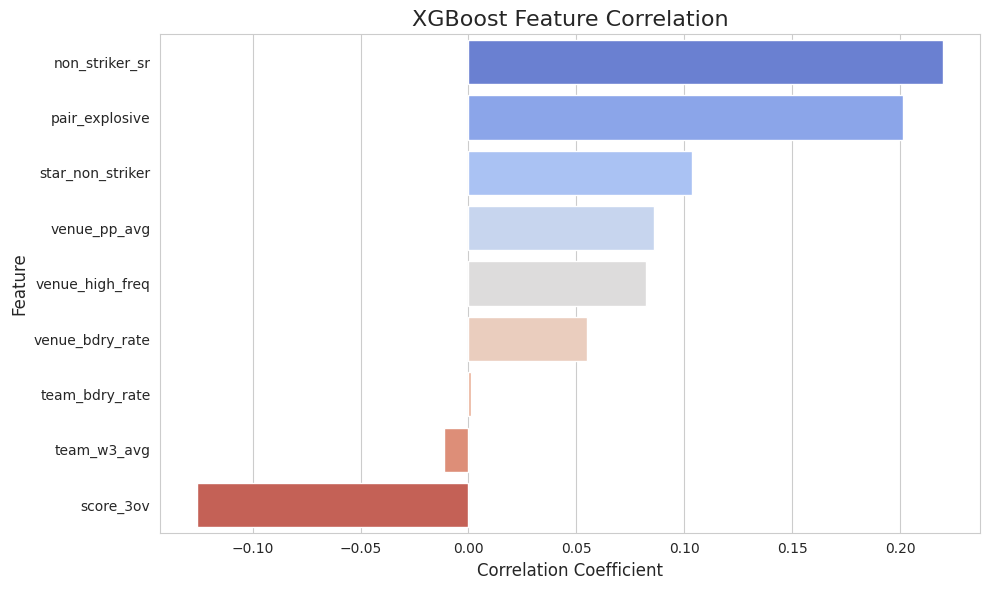

In [45]:
# Combine XGBoost features and target for correlation analysis
xgb_train_df = X_train_xgb.copy()
xgb_train_df['target_delta'] = y_train_xgb

# Calculate correlations with the target
xgb_correlations = xgb_train_df.corr()['target_delta'].drop('target_delta').sort_values(ascending=False)

# Plotting XGBoost feature-target correlations
plt.figure(figsize=(10, 6))
sns.barplot(x=xgb_correlations.values, y=xgb_correlations.index, palette='coolwarm')
plt.title('XGBoost Feature Correlation', fontsize=16)
plt.xlabel('Correlation Coefficient', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

#### XGBoost Inter-Feature Correlation Heatmap

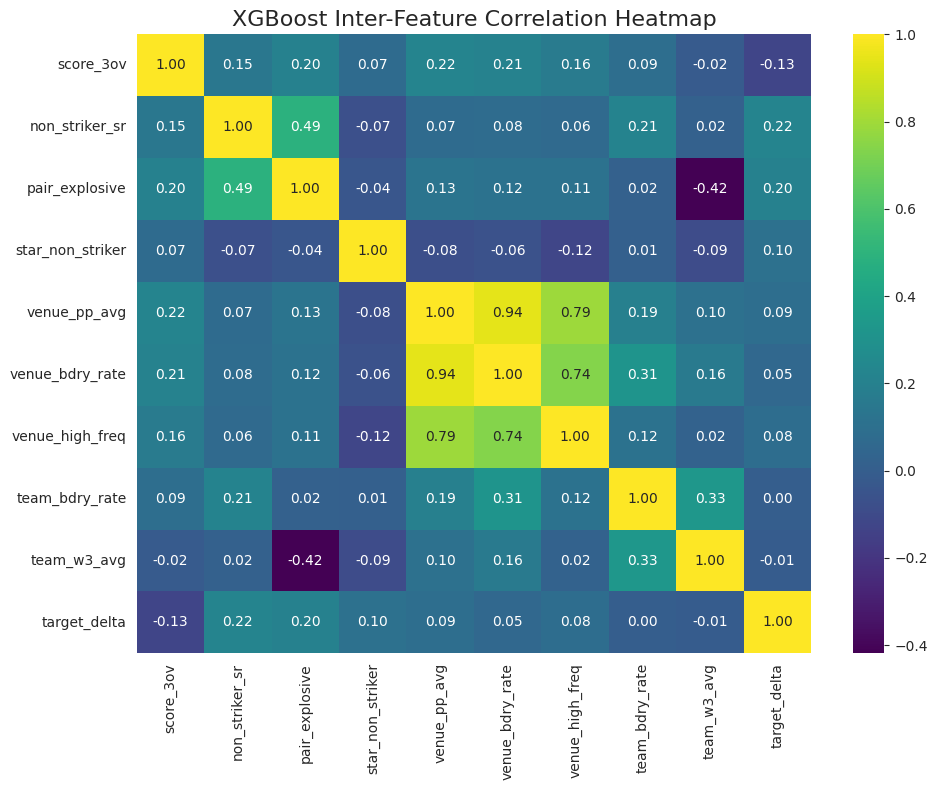

In [42]:
# Plotting XGBoost inter-feature correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(xgb_train_df.corr(), annot=True, cmap='viridis', fmt=".2f")
plt.title('XGBoost Inter-Feature Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

#### Random Forest Feature-Target Correlation

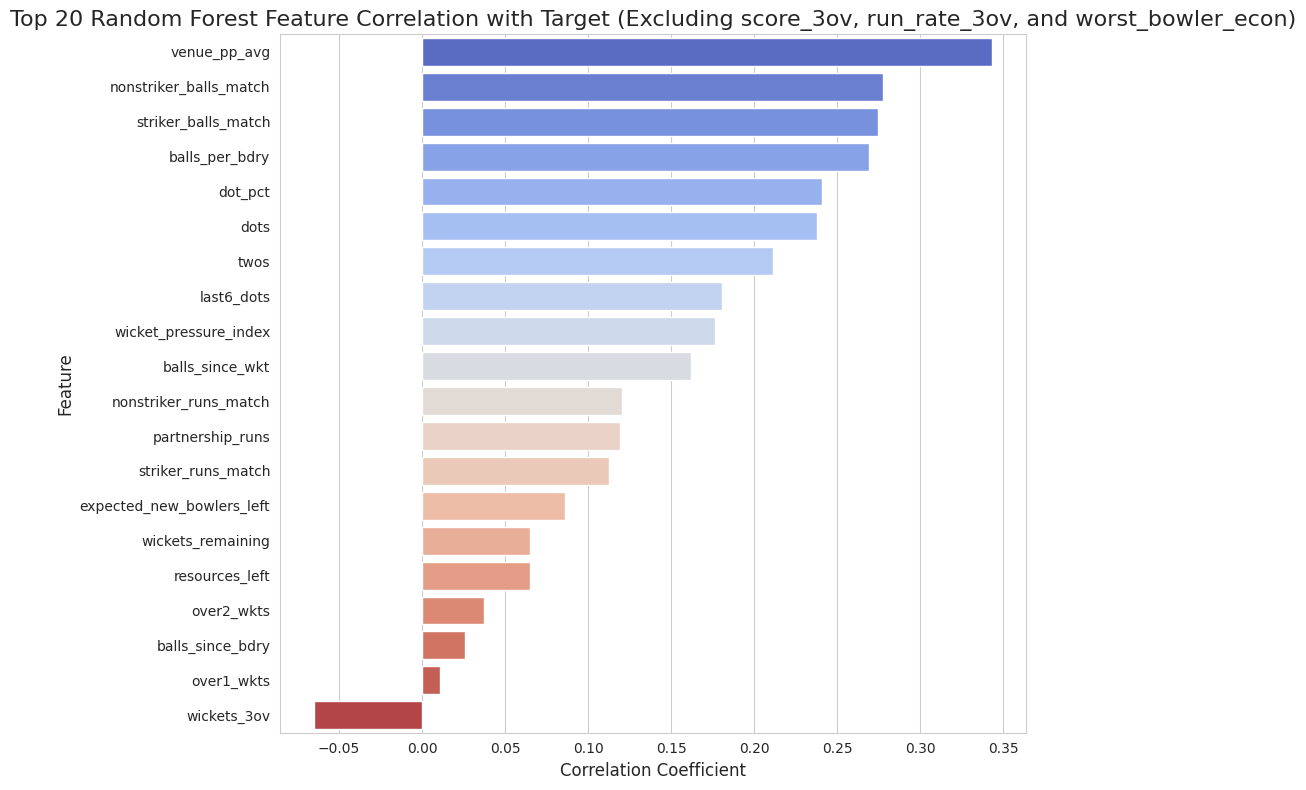

In [48]:
# Combine Random Forest features and target for correlation analysis
rf_train_df = X_train_rf.copy()
rf_train_df['target_delta'] = y_train_rf

# Calculate correlations with the target
rf_correlations = rf_train_df.corr()['target_delta'].drop('target_delta').sort_values(ascending=False)

# Remove specified features from correlation plot
features_to_remove_from_plot = ['run_rate_3ov', 'score_3ov', 'worst_bowler_econ']
rf_correlations_filtered = rf_correlations[~rf_correlations.index.isin(features_to_remove_from_plot)]

# Plotting Random Forest feature-target correlations (showing top 20 for readability)
plt.figure(figsize=(10, max(6, len(rf_correlations_filtered.head(20)) * 0.4)))
sns.barplot(x=rf_correlations_filtered.head(20).values, y=rf_correlations_filtered.head(20).index, palette='coolwarm')
plt.title('Top 20 Random Forest Feature Correlation with Target (Excluding score_3ov, run_rate_3ov, and worst_bowler_econ)', fontsize=16)
plt.xlabel('Correlation Coefficient', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

#### Random Forest Top 10 Inter-Feature Correlation Heatmap

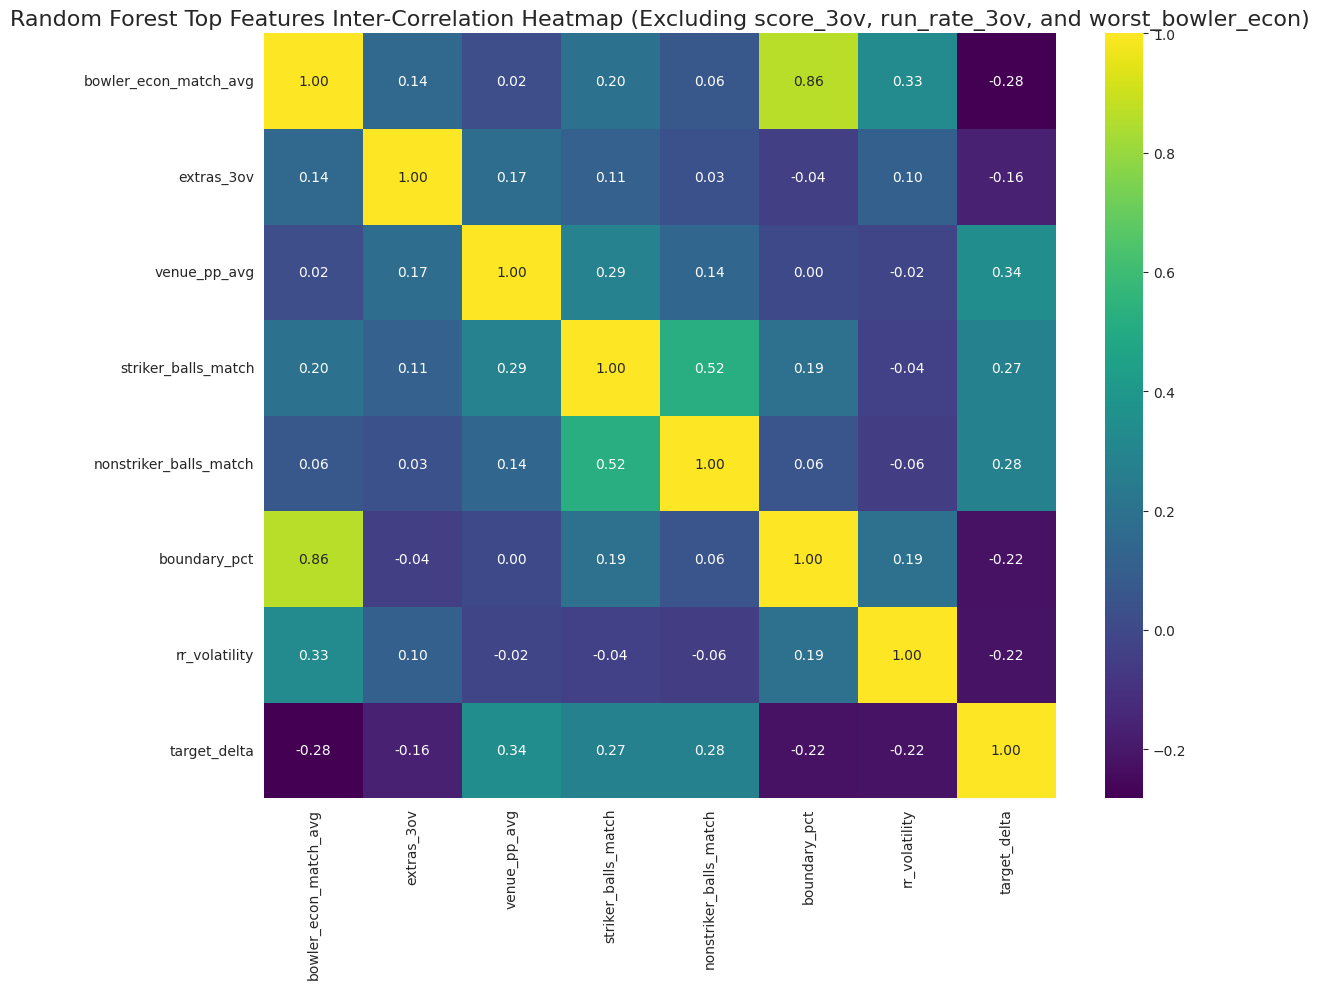

In [47]:
# Get the top 10 features from Random Forest importance analysis
rf_top_10_features = rf_importance_df['Feature'].head(10).tolist()

# Remove 'run_rate_3ov', 'score_3ov' and 'worst_bowler_econ' as requested
features_to_remove = ['run_rate_3ov', 'score_3ov', 'worst_bowler_econ']
rf_top_10_features = [f for f in rf_top_10_features if f not in features_to_remove]

# Create a DataFrame with only these top features and the target
rf_top_features_df = X_train_rf[rf_top_10_features].copy()
rf_top_features_df['target_delta'] = y_train_rf

# Plotting heatmap for top N Random Forest features + target
plt.figure(figsize=(12, 10))
sns.heatmap(rf_top_features_df.corr(), annot=True, cmap='viridis', fmt=".2f")
plt.title('Random Forest Top Features Inter-Correlation Heatmap (Excluding score_3ov, run_rate_3ov, and worst_bowler_econ)', fontsize=16)
plt.tight_layout()
plt.show()

Observing the above plots, we can clearly conclude that the features we have engineered have strong correlation with the dependent variable and intra feature correlation is insignificant (less redundancy in features).

# Justification for Model Selection: XGBoost and Random Forest

For predicting cricket scores, we've chosen an ensemble approach combining XGBoost and Random Forest models due to their complementary strengths in handling the non linear nature of cricket data.

**1. XGBoost (Extreme Gradient Boosting)**
*   **Strengths:** It is good at capturing complex non-linear relationships and interactions between features.

*   **Application in Cricket:** In low scoring phases in cricket, the data tends to be non-linear (since the batting team accelarates) which is where it performs well.

**2. Random Forest**
*   **Strengths:** Random Forest builds multiple decision trees during training and is hence robust to overfitting and outliers.

*   **Application in Cricket:** For higher-scoring phases of a match, where there might be more randomness or unexpected events (e.g., quick boundaries, sudden wickets), the robustness and generalization capabilities of Random Forest make it an excellent choice.

**3. Ensemble Approach: Combining Strengths**

The advantage of using both models is their ability to complement each other. The ensemble approach leverages this by:
*   **XGBoost as a 'Low-Score Specialist':** For innings where the score after 3 overs is low (e.g., less than 26), we would expect the data to follow a non-linear trend since the batting team may intend to accelarate scoring. This makes XGB the ideal choice for this setting.

*   **Random Forest as a 'High-Score Specialist':** When the score after 3 overs is higher, the inherent variability increases. Random Forest's ability to handle noisy data and generalize well helps it perform really well in this setting.

We empirically came up with the threshold of 26, our plots demonstrating the same are present below.

In [28]:
def build_xgb_pipeline():
    return XGBRegressor(
            objective="reg:squarederror",
            n_estimators=600, learning_rate=0.05, max_depth=5,
            subsample=0.8, colsample_bytree=0.8,
            min_child_weight=3, reg_alpha=0.1, reg_lambda=1.0,
            random_state=42, n_jobs=-1, verbosity=0,
        )

def build_rf_pipeline():
    return RandomForestRegressor(
            n_estimators=400, max_depth=None,
            min_samples_split=2, min_samples_leaf=2,
            max_features="sqrt",
            random_state=42, n_jobs=-1,
        )


In [55]:
min_train_year = TARGET_SEASON - WINDOW_N
train_ids = [m for m, d in id_to_date.items()
             if min_train_year <= d.year and d <  SPLIT_DATE]
test_ids  = [m for m, d in id_to_date.items()
             if d.year == TARGET_SEASON      and d >= SPLIT_DATE]

train_ids.sort(key=lambda m: id_to_date[m])
test_ids.sort(key=lambda m: id_to_date[m])

print(f"Train: {min_train_year}-01-01 → {SPLIT_DATE - datetime.timedelta(days=1)}  "
      f"({len(train_ids)} matches)")
print(f"Test : {SPLIT_DATE} → end of {TARGET_SEASON}                "
      f"({len(test_ids)} matches)")

print("\nBuilding player maps + H2H + historical stats from training window...")
pmaps = build_player_maps(train_ids)
hist  = compute_hist_stats(train_ids)
print(f"  strikers={len(pmaps['striker_avg'])}  bowlers={len(pmaps['bowler_avg'])}  "
      f"venues={len(hist['venue_pp'])}  H2H pairs={len(pmaps['h2h_balls'])}")

# ── Specialisation thresholds (on full 6-over PP score) ───────────────────
XGB_TRAIN_MAX = 70 # XGBoost trains only on matches where score_6ov <  70
RF_TRAIN_MIN  = 60 # RF      trains only on matches where score_6ov >= 60

# Build datasets (full pool) — y is the delta (overs 4-6)
X_train_xgb_full, y_train = build_dataset(train_ids, hist, pmaps)
X_test_xgb_full,  y_test  = build_dataset(test_ids,  hist, pmaps)
X_train_rf_full,  _       = build_rf_dataset(train_ids, hist, pmaps)
X_test_rf,        _       = build_rf_dataset(test_ids,  hist, pmaps)

# Reconstruct full 6-over score on the train rows: y = delta, so score_6ov = score_3ov + delta
score_6ov_train = X_train_xgb_full["score_3ov"].values + y_train

xgb_mask = score_6ov_train <  XGB_TRAIN_MAX
rf_mask  = score_6ov_train >= RF_TRAIN_MIN

# Specialised training subsets
X_train_xgb = X_train_xgb_full.loc[xgb_mask]
X_test_xgb = X_test_xgb_full
y_train_xgb = y_train[xgb_mask]
X_train_rf  = X_train_rf_full.loc[rf_mask]
y_train_rf  = y_train[rf_mask]

print(f"\nFull train pool: {len(y_train)} matches "
      f"(score_6ov: min={score_6ov_train.min():.0f} mean={score_6ov_train.mean():.1f} max={score_6ov_train.max():.0f})")
print(f"  XGB train (score_6ov < {XGB_TRAIN_MAX}): {int(xgb_mask.sum())} matches  "
      f"(mean delta={y_train_xgb.mean():.1f})")
print(f"  RF  train (score_6ov ≥ {RF_TRAIN_MIN}):  {int(rf_mask.sum())} matches  "
      f"(mean delta={y_train_rf.mean():.1f})")
print(f"  overlap (60 ≤ score_6ov < 70): {int((xgb_mask & rf_mask).sum())} matches in both")

# Fit
xgb_pipe = build_xgb_pipeline()
rf_pipe  = build_rf_pipeline()
xgb_pipe.fit(X_train_xgb.values, y_train_xgb)
rf_pipe.fit(X_train_rf.values,   y_train_rf)


artifacts_dir = os.path.join(os.getcwd(), "model_artifacts")
xgb_pipe.save_model(os.path.join(artifacts_dir, "xgb.json"))
import json
with open(os.path.join(artifacts_dir, "rf.pkl"),     "wb") as f:
      pickle.dump(rf_pipe, f)
with open(os.path.join(artifacts_dir, "xgb_feature_cols.csv"),     "w") as f:
      pd.DataFrame({"features": X_train_xgb_full.columns}).to_csv(f, index=False)
with open(os.path.join(artifacts_dir, "rf_feature_cols.csv"),     "w") as f:
      pd.DataFrame({"features": X_train_rf_full.columns}).to_csv(f, index=False)
with open(os.path.join(artifacts_dir, "historical_stats.json"), "w") as f:
      json.dump(hist, f, indent=4)
with open(os.path.join(artifacts_dir, "player_maps.json"),      "w") as f:
      json.dump(pmaps or {}, f, indent=4)
print(f"\nArtifacts saved to {artifacts_dir}/")

print("✅ XGBoost (low-score specialist) + RF (high-score specialist) fitted")


Train: 2023-01-01 → 2026-04-11  (237 matches)
Test : 2026-04-12 → end of 2026                (39 matches)

Building player maps + H2H + historical stats from training window...
  strikers=113  bowlers=146  venues=15  H2H pairs=4938

Full train pool: 237 matches (score_6ov: min=22 mean=55.3 max=125)
  XGB train (score_6ov < 70): 205 matches  (mean delta=27.2)
  RF  train (score_6ov ≥ 60):  78 matches  (mean delta=38.1)
  overlap (60 ≤ score_6ov < 70): 46 matches in both


XGBoostError: [18:22:56] /__w/xgboost/xgboost/dmlc-core/src/io/local_filesys.cc:224: Check failed: allow_null:  LocalFileSystem::Open "/content/model_artifacts/xgb.json": No such file or directory
Stack trace:
  [bt] (0) /usr/local/lib/python3.12/dist-packages/xgboost/lib/libxgboost.so(+0x2c1a8c) [0x7a0c166c1a8c]
  [bt] (1) /usr/local/lib/python3.12/dist-packages/xgboost/lib/libxgboost.so(+0x154e08d) [0x7a0c1794e08d]
  [bt] (2) /usr/local/lib/python3.12/dist-packages/xgboost/lib/libxgboost.so(+0x153a4a5) [0x7a0c1793a4a5]
  [bt] (3) /usr/local/lib/python3.12/dist-packages/xgboost/lib/libxgboost.so(XGBoosterSaveModel+0x4e) [0x7a0c165cd86e]
  [bt] (4) /lib/x86_64-linux-gnu/libffi.so.8(+0x7e2e) [0x7a0c5e2efe2e]
  [bt] (5) /lib/x86_64-linux-gnu/libffi.so.8(+0x4493) [0x7a0c5e2ec493]
  [bt] (6) /usr/lib/python3.12/lib-dynload/_ctypes.cpython-312-x86_64-linux-gnu.so(+0x98c1) [0x7a0c5f66c8c1]
  [bt] (7) /usr/lib/python3.12/lib-dynload/_ctypes.cpython-312-x86_64-linux-gnu.so(+0x8ffe) [0x7a0c5f66

In [31]:
PP_LOW_THRESHOLD = 26 # if score after 3 overs < 26 → use XGBoost, else → RF

# ── Per-model raw predictions (delta = runs in overs 4-6) ─────────────────
delta_xgb = np.clip(xgb_pipe.predict(X_test_xgb.values), 0, None)
delta_rf  = np.clip(rf_pipe.predict(X_test_rf.values),   0, None)

score_3ov  = X_test_xgb_full["score_3ov"].values
y_true_6ov = score_3ov + y_test
y_pred_xgb_full = score_3ov + np.clip(xgb_pipe.predict(X_test_xgb_full.values), 0, None)
y_pred_rf_full  = score_3ov + np.clip(rf_pipe.predict(X_test_rf.values), 0, None)


# ── Routed ensemble ───────────────────────────────────────────────────────
use_xgb     = score_3ov <= PP_LOW_THRESHOLD
chosen      = np.where(use_xgb, "XGB", "RF")
y_pred_dt  = np.where(use_xgb, y_pred_xgb_full, y_pred_rf_full)
y_pred_ens = np.where(use_xgb, y_pred_xgb_full, y_pred_rf_full)
print(y_pred_ens)
def metrics(name, y_true, y_pred):
    err = np.abs(y_true - y_pred)
    return {
        "model": name,
        "n":     int(len(y_true)),
        "RMSE":  float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE":   float(mean_absolute_error(y_true, y_pred)),
        "R2":    float(r2_score(y_true, y_pred)) if len(y_true) > 1 else float("nan"),
        "±5":    float((err <= 5).mean()  * 100),
        "±10":   float((err <= 10).mean() * 100),
    }

summary = pd.DataFrame([
    metrics("XGBoost (all)",      y_true_6ov, y_pred_xgb_full),
    metrics("RandomForest (all)", y_true_6ov, y_pred_rf_full),
    metrics("Routed ensemble",    y_true_6ov, y_pred_ens),
])
print(f"--- 2026 BACKTEST  (n={len(y_true_6ov)}, split={SPLIT_DATE}, route<{PP_LOW_THRESHOLD} → XGB) ---")
print(summary.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

# Build detailed results table for inspection
test_dates = [id_to_date.get(mid, "unknown") for mid in test_ids[:len(y_true_6ov)]]

results_df = pd.DataFrame({
    "date": test_dates,
    "match_id": test_ids[:len(y_true_6ov)],
    "score_3ov": score_3ov.astype(int),
    "pred_xgb": y_pred_xgb_full.astype(int),
    "pred_rf": y_pred_rf_full.astype(int),
    "pred_ensemble": y_pred_ens.astype(int),
    "actual_6ov": y_true_6ov.astype(int),
    "model_used": chosen,
    "error": np.abs(y_true_6ov - y_pred_ens).astype(int),
})

# Sort by date
results_df = results_df.sort_values("date").reset_index(drop=True)

print("=" * 140)
print(f"IPL 2026 PREDICTIONS: {len(results_df)} matches")
print("=" * 140)
print(results_df.to_string(index=True))

print("\n" + "=" * 140)
print("SUMMARY STATS")
print("=" * 140)
print(f"Mean prediction error (MAE): {results_df['error'].mean():.2f} runs")
print(f"RMSE: {np.sqrt((results_df['error'] ** 2).mean()):.2f} runs")
print(f"Median prediction error: {results_df['error'].median():.2f} runs")
print(f"Std dev: {results_df['error'].std():.2f} runs")
print(f"Within ±5 runs: {(results_df['error'] <= 5).mean() * 100:.1f}%")
print(f"Within ±10 runs: {(results_df['error'] <= 10).mean() * 100:.1f}%")
print(f"\nXGBoost used: {(results_df['model_used'] == 'XGB').sum()} matches")
print(f"RandomForest used: {(results_df['model_used'] == 'RF').sum()} matches")

[68.02684623 73.05917063 45.01624298 68.06633631 48.58288765 41.32120895
 44.25486946 68.53512599 39.81514931 57.77922821 52.0493145  45.05187416
 53.14358521 68.92502282 71.91804762 41.2416935  69.52135182 73.19122024
 54.8911972  22.43023491 33.29852295 70.25873214 71.50517523 65.9385119
 41.26130104 44.14335442 68.47814683 48.02326393 67.84465377 43.76857567
 78.37829563 67.64290774 68.77905952 75.90359325 72.3887004  66.10390278
 81.06532044 38.46251488 43.30032349]
--- 2026 BACKTEST  (n=39, split=2026-04-12, route<26 → XGB) ---
             model  n  RMSE   MAE   R2    ±5   ±10
     XGBoost (all) 39 15.06 12.68 0.27 17.95 41.03
RandomForest (all) 39 15.97 12.02 0.18 30.77 61.54
   Routed ensemble 39 12.79 10.12 0.48 25.64 58.97
IPL 2026 PREDICTIONS: 39 matches
          date match_id  score_3ov  pred_xgb  pred_rf  pred_ensemble  actual_6ov model_used  error
0   2026-04-12  1527692         30        57       68             68          60         RF      8
1   2026-04-12  1527693   

### Analyzing the Optimal `PP_LOW_THRESHOLD`

To understand why `PP_LOW_THRESHOLD = 26` was chosen as the optimal value, we can plot the ensemble model's performance (MAE and RMSE) across a range of possible threshold values. This visualization helps to identify the point at which the combined model performs best.

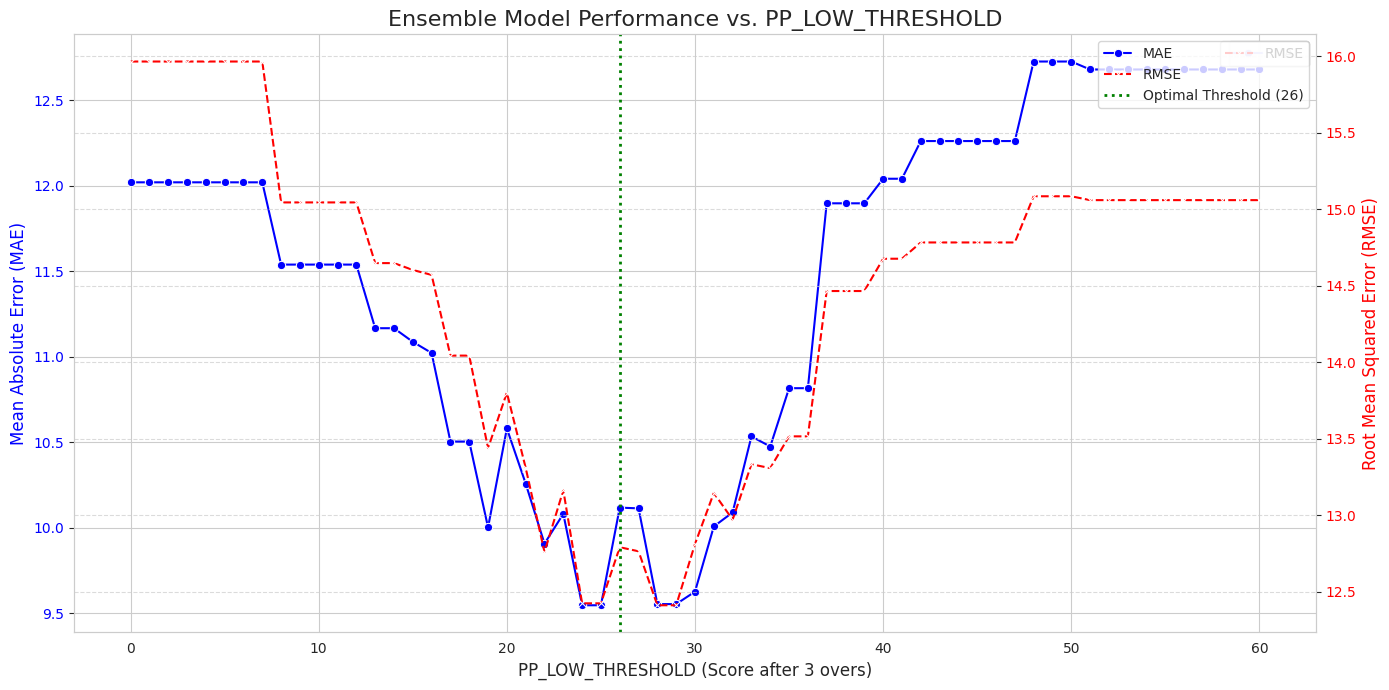

In [32]:
threshold_values = np.arange(0, 61, 1) # Test thresholds from 0 to 60
performance_data = []

for threshold in threshold_values:
    # Re-calculate `use_xgb` and `y_pred_ens` for the current threshold
    use_xgb_current = score_3ov <= threshold
    y_pred_ens_current = np.where(use_xgb_current, y_pred_xgb_full, y_pred_rf_full)

    # Calculate metrics for the current ensemble
    current_metrics = metrics("Routed ensemble", y_true_6ov, y_pred_ens_current)

    performance_data.append({
        'PP_LOW_THRESHOLD': threshold,
        'MAE': current_metrics['MAE'],
        'RMSE': current_metrics['RMSE']
    })

performance_df = pd.DataFrame(performance_data)

# Plotting the results
fig, ax1 = plt.subplots(figsize=(14, 7))

sns.lineplot(x='PP_LOW_THRESHOLD', y='MAE', data=performance_df, marker='o', label='MAE', ax=ax1, color='blue')
ax1.set_xlabel('PP_LOW_THRESHOLD (Score after 3 overs)', fontsize=12)
ax1.set_ylabel('Mean Absolute Error (MAE)', color='blue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx() # Create a second y-axis
sns.lineplot(x='PP_LOW_THRESHOLD', y='RMSE', data=performance_df, marker='x', label='RMSE', ax=ax2, color='red', linestyle='--')
ax2.set_ylabel('Root Mean Squared Error (RMSE)', color='red', fontsize=12)
ax2.tick_params(axis='y', labelcolor='red')

# Highlight the optimal threshold of 26
plt.axvline(x=PP_LOW_THRESHOLD, color='green', linestyle=':', linewidth=2, label=f'Optimal Threshold ({PP_LOW_THRESHOLD})')

# Add title and legends
plt.title('Ensemble Model Performance vs. PP_LOW_THRESHOLD', fontsize=16)
fig.legend(loc='upper right', bbox_to_anchor=(1, 1), bbox_transform=ax1.transAxes)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Comparing Ensemble vs. Individual Model Performance

To further show the benefits of the ensemble approach, we compare key performance metrics (MAE and RMSE) of the ensemble model against the individual XGBoost and Random Forest models.

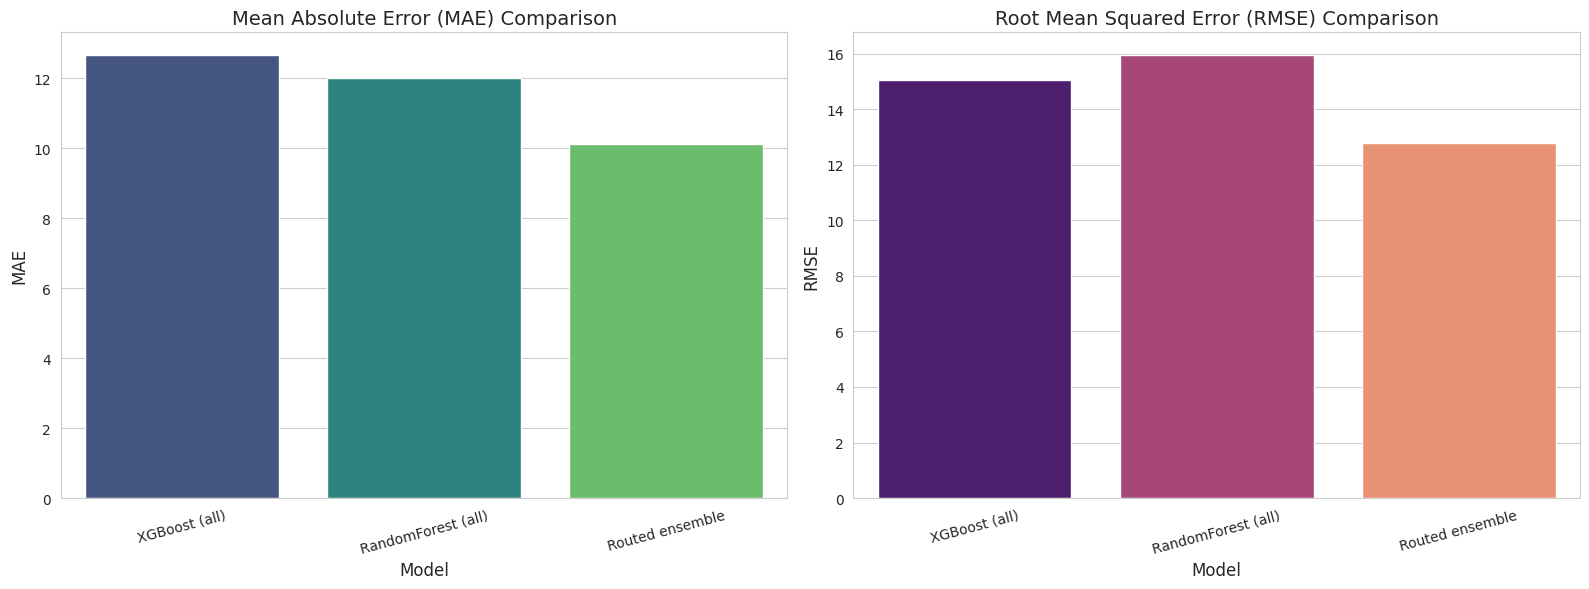

In [49]:
metrics_df = summary.set_index('model')[['MAE', 'RMSE']]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot MAE Comparison
sns.barplot(x=metrics_df.index, y='MAE', data=metrics_df, palette='viridis', ax=axes[0])
axes[0].set_title('Mean Absolute Error (MAE) Comparison', fontsize=14)
axes[0].set_ylabel('MAE', fontsize=12)
axes[0].set_xlabel('Model', fontsize=12)
axes[0].tick_params(axis='x', rotation=15)

# Plot RMSE Comparison
sns.barplot(x=metrics_df.index, y='RMSE', data=metrics_df, palette='magma', ax=axes[1])
axes[1].set_title('Root Mean Squared Error (RMSE) Comparison', fontsize=14)
axes[1].set_ylabel('RMSE', fontsize=12)
axes[1].set_xlabel('Model', fontsize=12)
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

### Model Performance by Initial Score (Score after 3 Overs)

To further justify the choice of XGBoost and Random Forest, and the ensemble strategy, we analyze how each model performs across different `score_3ov` ranges. This will highlight their 'specialist' roles – XGBoost for lower scores and Random Forest for higher scores.

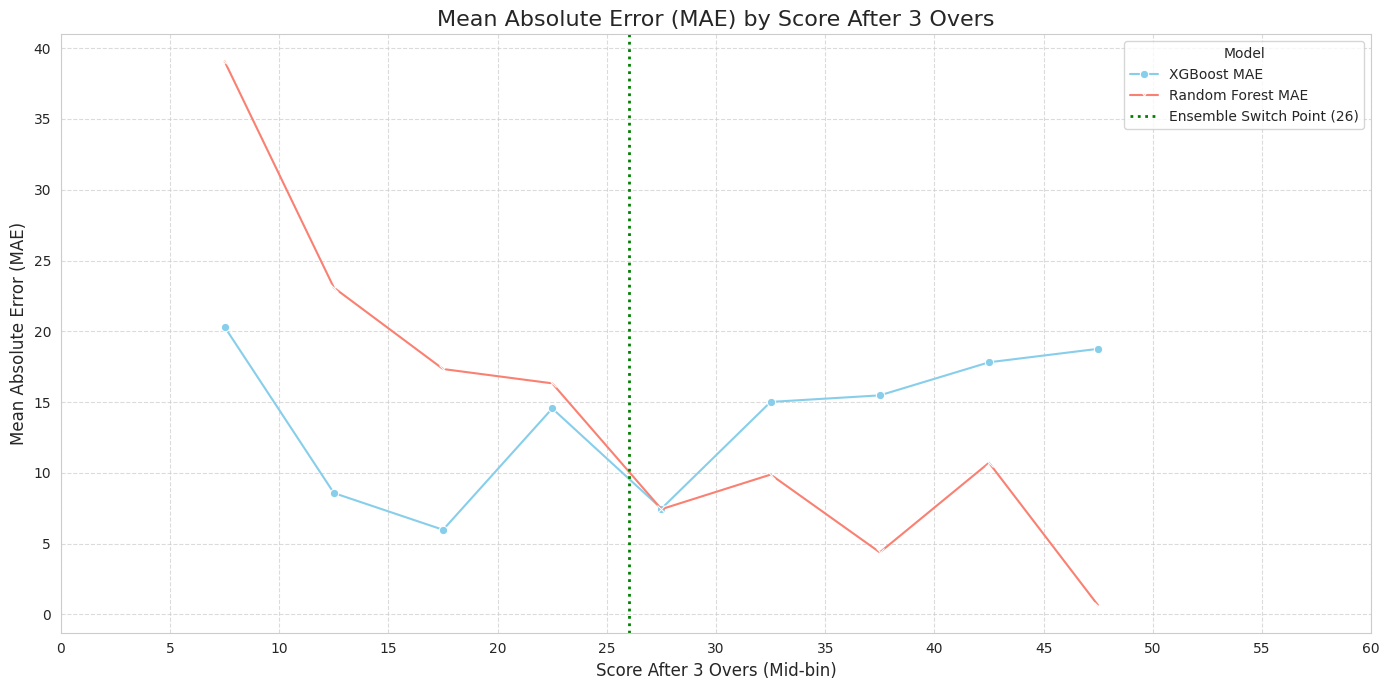

In [50]:
model_performance_by_3ov = pd.DataFrame({
    'score_3ov': score_3ov,
    'xgb_mae': np.abs(y_true_6ov - y_pred_xgb_full),
    'rf_mae': np.abs(y_true_6ov - y_pred_rf_full)
})

# Bin score_3ov for clearer visualization of trends
score_bins = pd.cut(model_performance_by_3ov['score_3ov'], bins=np.arange(0, 65, 5), right=False)

# Group by these bins and calculate mean MAE, explicitly selecting columns to avoid conflict
binned_performance = model_performance_by_3ov.groupby(score_bins, observed=False)[['xgb_mae', 'rf_mae']].mean().reset_index()
binned_performance['score_3ov_mid'] = binned_performance['score_3ov'].apply(lambda x: x.mid)

# Filter out the 50-55 bin (midpoint 52.5) as requested by the user
binned_performance = binned_performance[binned_performance['score_3ov_mid'] != 52.5]

fig, ax = plt.subplots(figsize=(14, 7))

sns.lineplot(x='score_3ov_mid', y='xgb_mae', data=binned_performance, marker='o', label='XGBoost MAE', color='skyblue', ax=ax)
sns.lineplot(x='score_3ov_mid', y='rf_mae', data=binned_performance, marker='x', label='Random Forest MAE', color='salmon', ax=ax)

plt.axvline(x=PP_LOW_THRESHOLD, color='green', linestyle=':', linewidth=2, label=f'Ensemble Switch Point ({PP_LOW_THRESHOLD})')

plt.title('Mean Absolute Error (MAE) by Score After 3 Overs', fontsize=16)
plt.xlabel('Score After 3 Overs (Mid-bin)', fontsize=12)
plt.ylabel('Mean Absolute Error (MAE)', fontsize=12)
plt.xticks(np.arange(0, 65, 5))
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Model')
plt.tight_layout()
plt.show()

### Feature Importance Analysis

This section analyzes the feature importance for both the XGBoost and Random Forest models to understand which features contribute most to their predictions. This helps in interpreting the models and refining feature engineering.

In [51]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [52]:
artifacts_dir = "/content/drive/MyDrive/model_artifacts"

xgb_feature_cols = pd.read_csv(os.path.join(artifacts_dir, "xgb_feature_cols.csv"))['features'].tolist()
rf_feature_cols = pd.read_csv(os.path.join(artifacts_dir, "rf_feature_cols.csv"))['features'].tolist()

# Load the trained XGB model
xgb_pipe_loaded = XGBRegressor()
xgb_pipe_loaded.load_model(os.path.join(artifacts_dir, "xgb.json"))

# Load the trained Random Forest model
with open(os.path.join(artifacts_dir, "rf.pkl"), "rb") as f:
    rf_pipe_loaded = pickle.load(f)

print("Models and feature columns loaded successfully!")

## XGBoost Feature Importance

# Feature importances for XGBoost
xgb_importances = xgb_pipe_loaded.feature_importances_

# DataFrame for XGBoost feature importances
xgb_importance_df = pd.DataFrame({
    'Feature': xgb_feature_cols,
    'Importance': xgb_importances
}).sort_values(by='Importance', ascending=False)

print("\nTop 10 XGBoost Features:")
display(xgb_importance_df.head(10))

## Random Forest Feature Importance

# Feature importances for Random Forest
rf_importances = rf_pipe_loaded.feature_importances_

# DataFrame for Random Forest feature importances
rf_importance_df = pd.DataFrame({
    'Feature': rf_feature_cols,
    'Importance': rf_importances
}).sort_values(by='Importance', ascending=False)

print("\nTop 10 Random Forest Features:")
display(rf_importance_df.head(10))


Models and feature columns loaded successfully!

Top 10 XGBoost Features:


,Feature,Importance
3,star_non_striker,0.226672
1,non_striker_sr,0.109226
2,pair_explosive,0.104596
0,score_3ov,0.103651
6,venue_high_freq,0.102376
8,team_w3_avg,0.092415
4,venue_pp_avg,0.091677
7,team_bdry_rate,0.085152
5,venue_bdry_rate,0.084235



Top 10 Random Forest Features:


,Feature,Importance
43,bowler_econ_match_avg,0.063856
9,run_rate_3ov,0.045292
0,score_3ov,0.042824
2,extras_3ov,0.042083
46,venue_pp_avg,0.039516
35,striker_balls_match,0.036832
38,nonstriker_balls_match,0.035715
21,boundary_pct,0.035050
12,rr_volatility,0.033886
44,worst_bowler_econ,0.033431


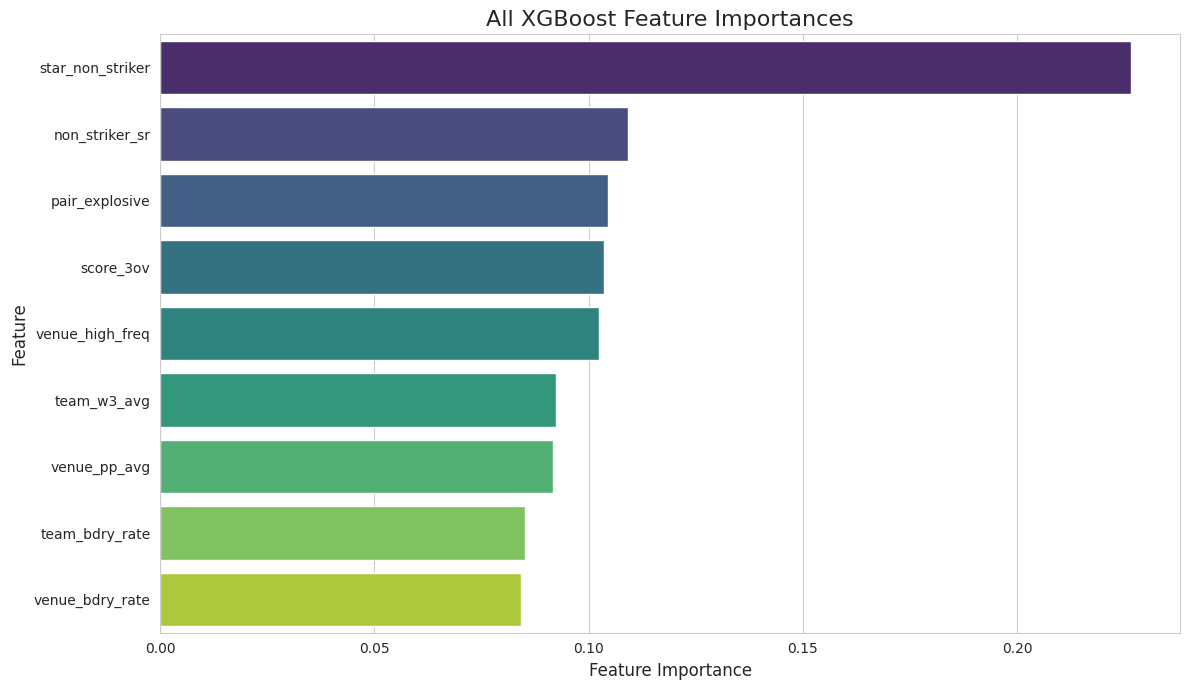

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# --- XGBoost Feature Importance Plot ---
plt.figure(figsize=(12, max(7, len(xgb_importance_df) * 0.4))) # Adjust figure size dynamically
sns.barplot(x='Importance', y='Feature', data=xgb_importance_df, palette='viridis')
plt.title('All XGBoost Feature Importances', fontsize=16)
plt.xlabel('Feature Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()


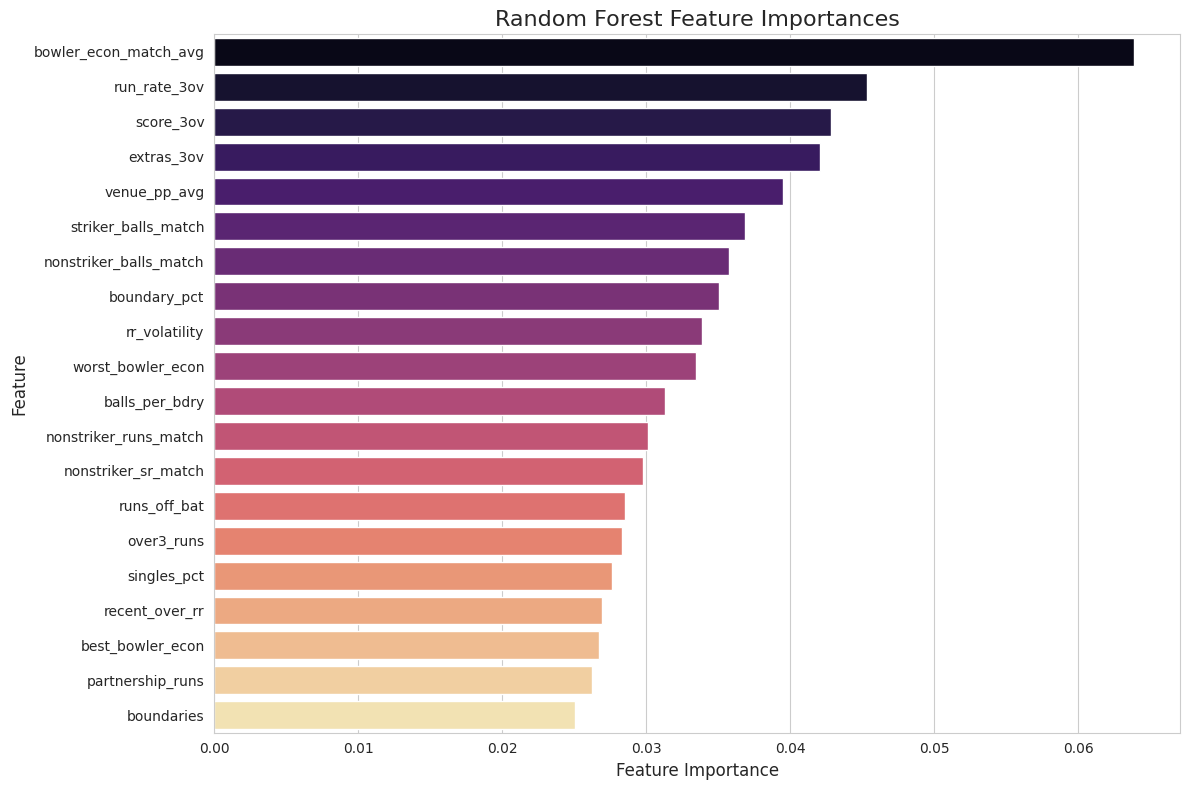

In [54]:
sns.set_style("whitegrid")

rf_importance = rf_importance_df.head(20)

plt.figure(figsize=(12, max(7, len(rf_importance) * 0.4))) # Adjust figure size dynamically
sns.barplot(x='Importance', y='Feature', data=rf_importance, palette='magma')
plt.title('Random Forest Feature Importances', fontsize=16)
plt.xlabel('Feature Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()